# QSAR CHOK1 — Graphormer & GraphGPS (Classification)

Binary classification pipeline matching `qsar_chok1.ipynb`:
- Same label encoding: score ≥ 40 → Active (1) | score = 0 → Inactive (0) | inconclusive dropped
- Same test set: 20 % stratified holdout (SEED = 42)
- Same metrics: Sensitivity, Specificity, CCR, ROC-AUC, PR-AUC, MCC, Bal-Acc, F1 @ CPT = 0.5 & 0.8

Two advanced graph transformer architectures added:
- **Graphormer** (Ying et al., NeurIPS 2021) — centrality encoding + multi-head TransformerConv
- **GraphGPS** (Rampášek et al., NeurIPS 2022) — Laplacian eigenvector PE + GINEConv + global attention


In [2]:
import subprocess, sys
def _install(pkg):
    subprocess.check_call([sys.executable,'-m','pip','install','-q',pkg])
for pkg in ['rdkit','xgboost','imbalanced-learn','scikit-learn',
            'matplotlib','seaborn','openpyxl','torch','torch-geometric']:
    try: __import__(pkg.replace('-','_'))
    except ImportError: _install(pkg)
print('Dependencies OK.')


Dependencies OK.


In [3]:
import warnings; warnings.filterwarnings('ignore')
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
import copy, time

from rdkit import Chem
from rdkit.Chem import AllChem, rdchem, DataStructs

import torch, torch.nn as nn, torch.nn.functional as F
from torch_geometric.nn import (TransformerConv, GINEConv, GPSConv, global_mean_pool)
from torch_geometric.utils import (degree as pyg_degree, get_laplacian, to_dense_adj)
from torch_geometric.data import Data
from torch_geometric.loader import DataLoader
from torch.nn import Linear, Sequential

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    roc_auc_score, average_precision_score, matthews_corrcoef,
    balanced_accuracy_score, f1_score, confusion_matrix,
    roc_curve, precision_recall_curve, classification_report
)

SEED   = 42
PE_DIM = 8        # Laplacian eigenvectors for GraphGPS
np.random.seed(SEED)
torch.manual_seed(SEED)
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

DATASET_NAME = 'CHOK1'
ASSAY_ID     = 'AID_1346980'
OUT_PREFIX   = 'chok1_gt'

METRIC_COLS = ['Model','CPT','Sensitivity','Specificity','CCR',
               'ROC-AUC','PR-AUC','MCC','Bal-Acc','F1']

print(f'Dataset : {DATASET_NAME}  ({ASSAY_ID})')
print(f'Device  : {DEVICE}')


Dataset : CHOK1  (AID_1346980)
Device  : cpu


---
## Step 1 — Data Loading, Curation & Label Assignment


In [4]:
COLS = ['PUBCHEM_CID','PUBCHEM_EXT_DATASOURCE_SMILES',
        'PUBCHEM_ACTIVITY_SCORE','PUBCHEM_ACTIVITY_OUTCOME']

df_raw = pd.read_csv('AID_1346980_cleaned.csv', usecols=COLS)
print(f'Raw rows : {len(df_raw):,}')
print(df_raw['PUBCHEM_ACTIVITY_OUTCOME'].value_counts())
print(df_raw['PUBCHEM_ACTIVITY_SCORE'].describe().round(2))


Raw rows : 7,671
PUBCHEM_ACTIVITY_OUTCOME
Inactive        7320
Inconclusive     236
Active           115
Name: count, dtype: int64
count    7671.00
mean        1.19
std         7.45
min         0.00
25%         0.00
50%         0.00
75%         0.00
max        90.00
Name: PUBCHEM_ACTIVITY_SCORE, dtype: float64


In [5]:
def canonicalize(smi):
    try:
        mol = Chem.MolFromSmiles(str(smi))
        return Chem.MolToSmiles(mol) if mol else None
    except: return None

df_raw['csmi'] = df_raw['PUBCHEM_EXT_DATASOURCE_SMILES'].apply(canonicalize)
df = df_raw.dropna(subset=['csmi'])
print(f'After parse : {len(df):,}  (removed {len(df_raw)-len(df)} invalid SMILES)')
df = df.drop_duplicates('csmi', keep='first').reset_index(drop=True)
print(f'After dedup : {len(df):,}')


[08:44:28] WARNING: not removing hydrogen atom without neighbors


After parse : 7,671  (removed 0 invalid SMILES)
After dedup : 7,671


Removed 236 inconclusive
Active   (1): 115
Inactive (0): 7,320
Ratio       : 63.7:1


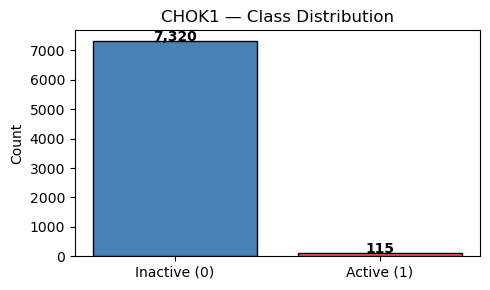

In [6]:
# Active (score >= 40) -> 1 | Inactive (score = 0) -> 0 | Inconclusive -> drop
df['label'] = df['PUBCHEM_ACTIVITY_SCORE'].apply(
    lambda s: 1 if s >= 40 else (0 if s == 0 else np.nan))
n_inc = df['label'].isna().sum()
df    = df.dropna(subset=['label']).copy()
df['label'] = df['label'].astype(int)

n_act, n_ina = (df['label']==1).sum(), (df['label']==0).sum()
print(f'Removed {n_inc:,} inconclusive')
print(f'Active   (1): {n_act:,}')
print(f'Inactive (0): {n_ina:,}')
print(f'Ratio       : {n_ina/n_act:.1f}:1')

fig, ax = plt.subplots(figsize=(5,3))
bars = ax.bar(['Inactive (0)','Active (1)'], [n_ina, n_act],
              color=['steelblue','tomato'], edgecolor='black')
for b, v in zip(bars, [n_ina, n_act]):
    ax.text(b.get_x()+b.get_width()/2, v+5, f'{v:,}', ha='center', fontweight='bold')
ax.set_title(f'{DATASET_NAME} — Class Distribution')
ax.set_ylabel('Count')
plt.tight_layout()
plt.savefig(f'{OUT_PREFIX}_class_dist.png', dpi=150)
plt.show()


---
## Step 2 — Feature Engineering

### 2A. Rich Atom/Bond Graph Features (same as `qsar_mito.ipynb`)
- **Atom (27-dim)**: atomic-num one-hot (10), degree one-hot (6), formal-charge (3), hybridization (4), is_aromatic, is_in_ring, total_Hs (normalised), mass (normalised)
- **Bond (6-dim)**: bond-type one-hot (4), is_conjugated, is_in_ring


In [7]:
ATOM_SYMBOLS = [6, 7, 8, 16, 9, 15, 17, 35, 53]   # C N O S F P Cl Br I

def one_hot(val, choices):
    vec = [0] * len(choices)
    try: vec[choices.index(val)] = 1
    except ValueError: pass
    return vec

HYBRID_MAP = {
    rdchem.HybridizationType.SP : 0,
    rdchem.HybridizationType.SP2: 1,
    rdchem.HybridizationType.SP3: 2,
}

def atom_feat(atom):
    at_oh = one_hot(atom.GetAtomicNum(), ATOM_SYMBOLS) + [0]          # 10-dim
    deg   = min(atom.GetDegree(), 5)
    deg_oh = [0]*6; deg_oh[deg] = 1                                    #  6-dim
    fc    = atom.GetFormalCharge()
    fc_enc = [1 if fc<0 else 0, 1 if fc==0 else 0, 1 if fc>0 else 0] #  3-dim
    hyb   = [0,0,0,0]
    hyb[HYBRID_MAP.get(atom.GetHybridization(), 3)] = 1                #  4-dim
    extras = [
        int(atom.GetIsAromatic()),
        int(atom.IsInRing()),
        min(atom.GetTotalNumHs(), 4) / 4.0,
        atom.GetMass() / 100.0,
    ]                                                                   #  4-dim
    return at_oh + deg_oh + fc_enc + hyb + extras   # total = 27-dim

BOND_TYPES = [
    rdchem.BondType.SINGLE,
    rdchem.BondType.DOUBLE,
    rdchem.BondType.TRIPLE,
    rdchem.BondType.AROMATIC,
]

def bond_feat(bond):
    bt_oh = one_hot(bond.GetBondType(), BOND_TYPES)   # 4-dim
    return bt_oh + [int(bond.GetIsConjugated()), int(bond.IsInRing())]  # 6-dim

ATOM_DIM = 27
BOND_DIM = 6
print(f'ATOM_DIM={ATOM_DIM}  BOND_DIM={BOND_DIM}')


ATOM_DIM=27  BOND_DIM=6


In [8]:
def mol_to_graph(smi, label):
    mol = Chem.MolFromSmiles(smi)
    if mol is None: return None
    x = torch.tensor([atom_feat(a) for a in mol.GetAtoms()], dtype=torch.float)
    ei, ea = [], []
    for bond in mol.GetBonds():
        i, j = bond.GetBeginAtomIdx(), bond.GetEndAtomIdx()
        bf = bond_feat(bond)
        ei += [[i,j],[j,i]]; ea += [bf, bf]
    if ei:
        edge_index = torch.tensor(ei, dtype=torch.long).t().contiguous()
        edge_attr  = torch.tensor(ea, dtype=torch.float)
    else:
        edge_index = torch.zeros((2,0), dtype=torch.long)
        edge_attr  = torch.zeros((0, BOND_DIM), dtype=torch.float)
    y = torch.tensor([float(label)], dtype=torch.float)
    return Data(x=x, edge_index=edge_index, edge_attr=edge_attr, y=y)

y_all      = df['label'].values
graph_list = []
for smi, lbl in zip(df['csmi'].values, y_all):
    g = mol_to_graph(smi, lbl)
    if g: graph_list.append(g)

print(f'Graphs built: {len(graph_list):,}')
print(f'Example: {graph_list[0]}')


Graphs built: 7,435
Example: Data(x=[5, 27], edge_index=[2, 8], edge_attr=[8, 6], y=[1])


---
## Step 3 — Laplacian Eigenvector PE (GraphGPS only)

Compute the k = 8 smallest non-trivial eigenvectors of the normalised graph Laplacian
and store them as a node attribute `pe`. Molecules with < 3 atoms get zero-padded PE.


In [9]:
def compute_laplacian_pe(data, k=PE_DIM):
    n = data.num_nodes
    if n <= 2:
        return torch.zeros(n, k)
    ei, ew = get_laplacian(data.edge_index, normalization='sym', num_nodes=n)
    L = to_dense_adj(ei, edge_attr=ew, max_num_nodes=n).squeeze(0).numpy()
    try:
        import numpy.linalg as nla
        _, vecs = nla.eigh(L)
        num_take = min(k, n - 1)
        pe = torch.from_numpy(vecs[:, 1:1+num_take]).float()
        if pe.shape[1] < k:
            pe = F.pad(pe, (0, k - pe.shape[1]))
    except Exception:
        pe = torch.zeros(n, k)
    return pe

# Augment each graph with its Laplacian PE (used only by GraphGPS loader)
graph_list_gps = []
for d in graph_list:
    pe = compute_laplacian_pe(d)
    graph_list_gps.append(
        Data(x=d.x, edge_index=d.edge_index, edge_attr=d.edge_attr, y=d.y, pe=pe)
    )

print(f'Laplacian PE (dim={PE_DIM}) added to {len(graph_list_gps):,} graphs.')


Laplacian PE (dim=8) added to 7,435 graphs.


---
## Step 4 — 80 / 20 / 20 Split + Downsampling

Matches `qsar_mito.ipynb` exactly:
1. **20 % stratified external test** — held out completely.
2. **80 / 20 stratified train / val** split on the remaining pool.
3. **1 : 1 downsampling** of inactives in the TRAIN set only (Hao Zhu method).
   Validation and test keep the real-world class imbalance.


In [10]:
idx_all = np.arange(len(y_all))

# 20 % external test (stratified)
idx_pool, idx_test = train_test_split(
    idx_all, test_size=0.20, stratify=y_all, random_state=SEED)

graphs_pool = [graph_list[i] for i in idx_pool]
graphs_test = [graph_list[i] for i in idx_test]
gps_pool    = [graph_list_gps[i] for i in idx_pool]
gps_test    = [graph_list_gps[i] for i in idx_test]

y_pool = y_all[idx_pool]
y_test = y_all[idx_test]

print(f'Pool : {len(y_pool):,}  act={(y_pool==1).sum()}  ina={(y_pool==0).sum()}')
print(f'Test : {len(y_test):,}  act={(y_test==1).sum()}  ina={(y_test==0).sum()}')


Pool : 5,948  act=92  ina=5856
Test : 1,487  act=23  ina=1464


In [11]:
pool_sub = np.arange(len(y_pool))
tr_sub, val_sub = train_test_split(
    pool_sub, test_size=0.20, stratify=y_pool, random_state=SEED)

graphs_val    = [graphs_pool[i] for i in val_sub]
graphs_trraw  = [graphs_pool[i] for i in tr_sub]
gps_val       = [gps_pool[i] for i in val_sub]
gps_trraw     = [gps_pool[i] for i in tr_sub]

y_val    = y_pool[val_sub]
y_tr_raw = y_pool[tr_sub]

print(f'Train-raw: {len(y_tr_raw):,}  act={(y_tr_raw==1).sum()}  ina={(y_tr_raw==0).sum()}')
print(f'Val      : {len(y_val):,}  act={(y_val==1).sum()}  ina={(y_val==0).sum()}')

# 1:1 downsampling of TRAIN inactives (Hao Zhu method)
act_idx = np.where(y_tr_raw == 1)[0]
ina_idx = np.where(y_tr_raw == 0)[0]
rng = np.random.RandomState(SEED)
sampled_ina = rng.choice(ina_idx, size=len(act_idx), replace=False)
train_idx   = np.concatenate([act_idx, sampled_ina])
rng.shuffle(train_idx)

y_train       = y_tr_raw[train_idx]
graphs_train  = [graphs_trraw[i] for i in train_idx]
gps_train     = [gps_trraw[i]   for i in train_idx]

print(f'Balanced TRAIN: {len(y_train):,}  act={(y_train==1).sum()} / ina={(y_train==0).sum()} (1:1)')


Train-raw: 4,758  act=74  ina=4684
Val      : 1,190  act=18  ina=1172
Balanced TRAIN: 148  act=74 / ina=74 (1:1)


---
## Step 5 — Evaluation Helpers

Identical metric set to `qsar_mito.ipynb` — evaluated at CPT = 0.5 and CPT = 0.8.


In [12]:
def evaluate(y_true, y_prob, name, cpt=0.5):
    y_pred = (y_prob >= cpt).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred).ravel()
    sens = tp/(tp+fn) if (tp+fn) > 0 else 0.0
    spec = tn/(tn+fp) if (tn+fp) > 0 else 0.0
    return {
        'Model'      : name,
        'CPT'        : cpt,
        'Sensitivity': round(sens*100, 1),
        'Specificity': round(spec*100, 1),
        'CCR'        : round((sens+spec)/2*100, 1),
        'ROC-AUC'    : round(roc_auc_score(y_true, y_prob), 4),
        'PR-AUC'     : round(average_precision_score(y_true, y_prob), 4),
        'MCC'        : round(matthews_corrcoef(y_true, y_pred), 4),
        'Bal-Acc'    : round(balanced_accuracy_score(y_true, y_pred)*100, 1),
        'F1'         : round(f1_score(y_true, y_pred), 4),
        'TP':tp, 'TN':tn, 'FP':fp, 'FN':fn,
    }

print('Metrics helper ready.')
print(f'Columns: {METRIC_COLS}')


Metrics helper ready.
Columns: ['Model', 'CPT', 'Sensitivity', 'Specificity', 'CCR', 'ROC-AUC', 'PR-AUC', 'MCC', 'Bal-Acc', 'F1']


---
## Step 6 — Graph Transformer Models

### Graphormer
Key innovations from Ying et al. NeurIPS 2021:
1. **Centrality encoding** — node degree embedded and added to input representation
2. **Multi-head attention** — `TransformerConv` conditioned on bond features
3. **Transformer blocks** — LayerNorm + GELU FFN + residual connections

### GraphGPS
Key innovations from Rampášek et al. NeurIPS 2022:
1. **Laplacian PE** — global eigenvector encoding projected into node features
2. **Local MPNN** — `GINEConv` for neighbourhood aggregation with bond features
3. **Global attention** — `MultiheadAttention` over all atoms in each molecule

Both models output a **scalar logit** → `BCEWithLogitsLoss` → `sigmoid` for probabilities.  
Input: ATOM_DIM=27, BOND_DIM=6


In [13]:
# ── Graphormer ────────────────────────────────────────────────────────────────
class GraphormerLayer(nn.Module):
    """Graphormer block: TransformerConv → LN + residual → FFN → LN + residual."""
    def __init__(self, hidden, num_heads, edge_dim=BOND_DIM, dropout=0.3):
        super().__init__()
        assert hidden % num_heads == 0
        head_dim = hidden // num_heads
        self.attn = TransformerConv(hidden, head_dim, heads=num_heads,
                                    concat=True, edge_dim=edge_dim,
                                    dropout=dropout, beta=True)
        self.norm1 = nn.LayerNorm(hidden)
        self.ffn   = nn.Sequential(
            nn.Linear(hidden, hidden*2), nn.GELU(),
            nn.Dropout(dropout), nn.Linear(hidden*2, hidden)
        )
        self.norm2 = nn.LayerNorm(hidden)
        self.drop  = nn.Dropout(dropout)

    def forward(self, x, edge_index, edge_attr):
        x = self.norm1(x + self.drop(self.attn(x, edge_index, edge_attr)))
        x = self.norm2(x + self.drop(self.ffn(x)))
        return x


class GraphormerModel(nn.Module):
    """Graphormer-inspired graph transformer for binary molecular classification."""
    def __init__(self, in_dim=ATOM_DIM, hidden=128, num_heads=4,
                 num_layers=3, dropout=0.3):
        super().__init__()
        torch.manual_seed(SEED)
        self.node_emb   = nn.Linear(in_dim, hidden)
        self.degree_emb = nn.Embedding(100, hidden)   # centrality encoding
        self.layers = nn.ModuleList([
            GraphormerLayer(hidden, num_heads, BOND_DIM, dropout)
            for _ in range(num_layers)
        ])
        self.drop = nn.Dropout(dropout)
        self.head = nn.Sequential(
            nn.Linear(hidden, hidden//2), nn.ReLU(),
            nn.Dropout(dropout), nn.Linear(hidden//2, 1)
        )

    def forward(self, x, edge_index, edge_attr, batch):
        h   = self.node_emb(x)
        deg = pyg_degree(edge_index[0], num_nodes=x.size(0)).long().clamp(max=99)
        h   = h + self.degree_emb(deg)
        h   = F.relu(h)
        h   = self.drop(h)
        for layer in self.layers:
            h = layer(h, edge_index, edge_attr)
        h = global_mean_pool(h, batch)
        return self.head(h).squeeze(-1)     # scalar logit per graph


print('GraphormerModel defined.')


GraphormerModel defined.


In [14]:
# ── GraphGPS ──────────────────────────────────────────────────────────────────
class GraphGPSModel(nn.Module):
    """
    GraphGPS: Laplacian PE + local GINEConv + global MultiheadAttention.
    Reference: Rampásek et al., NeurIPS 2022 (arXiv:2205.12454)
    """
    def __init__(self, in_dim=ATOM_DIM, hidden=128, pe_dim=PE_DIM,
                 num_heads=4, num_layers=3, dropout=0.3):
        super().__init__()
        torch.manual_seed(SEED)
        assert hidden % num_heads == 0
        self.node_emb = nn.Linear(in_dim, hidden)
        self.pe_emb   = nn.Linear(pe_dim, hidden)
        self.gps_layers = nn.ModuleList()
        for _ in range(num_layers):
            mlp  = nn.Sequential(
                nn.Linear(hidden, hidden*2), nn.GELU(),
                nn.Linear(hidden*2, hidden)
            )
            conv = GINEConv(mlp, edge_dim=BOND_DIM)
            gps  = GPSConv(channels=hidden, conv=conv, heads=num_heads,
                           dropout=dropout, norm='layer_norm', attn_type='multihead')
            self.gps_layers.append(gps)
        self.drop = nn.Dropout(dropout)
        self.head = nn.Sequential(
            nn.Linear(hidden, hidden//2), nn.ReLU(),
            nn.Dropout(dropout), nn.Linear(hidden//2, 1)
        )

    def forward(self, x, edge_index, edge_attr, batch, pe):
        h = self.node_emb(x) + self.pe_emb(pe)
        h = F.relu(h)
        h = self.drop(h)
        for gps in self.gps_layers:
            h = gps(h, edge_index, batch, edge_attr=edge_attr)
        h = global_mean_pool(h, batch)
        return self.head(h).squeeze(-1)     # scalar logit per graph


print('GraphGPSModel defined.')


GraphGPSModel defined.


---
## Step 7 — Training Infrastructure

- **Loss**: `BCEWithLogitsLoss` with `pos_weight` to handle class imbalance
- **Optimiser**: Adam
- **Early stopping**: patience = 20 epochs on val ROC-AUC (matches existing GNN protocol)
- **Batch size**: 64


In [15]:
BATCH      = 64
MAX_EPOCHS = 100
PATIENCE   = 20

# DataLoaders
train_loader     = DataLoader(graphs_train, batch_size=BATCH, shuffle=True)
val_loader       = DataLoader(graphs_val,   batch_size=BATCH, shuffle=False)
test_loader      = DataLoader(graphs_test,  batch_size=BATCH, shuffle=False)
train_loader_gps = DataLoader(gps_train,   batch_size=BATCH, shuffle=True)
val_loader_gps   = DataLoader(gps_val,     batch_size=BATCH, shuffle=False)
test_loader_gps  = DataLoader(gps_test,    batch_size=BATCH, shuffle=False)

# pos_weight = ratio of inactives to actives in balanced TRAIN set (≈1 here)
pos_w     = torch.tensor([(y_train==0).sum()/(y_train==1).sum()], device=DEVICE)
criterion = nn.BCEWithLogitsLoss(pos_weight=pos_w)

print(f'Train:{len(graphs_train)}  Val:{len(graphs_val)}  Test:{len(graphs_test)}')
print(f'pos_weight: {pos_w.item():.3f}')


def gt_train(model, optimizer, loader, has_pe=False):
    model.train()
    total = 0
    for batch in loader:
        batch = batch.to(DEVICE)
        optimizer.zero_grad()
        logit = (model(batch.x, batch.edge_index, batch.edge_attr, batch.batch, batch.pe)
                 if has_pe else
                 model(batch.x, batch.edge_index, batch.edge_attr, batch.batch))
        loss  = criterion(logit, batch.y)
        loss.backward()
        optimizer.step()
        total += loss.item() * batch.num_graphs
    return total / len(loader.dataset)


@torch.no_grad()
def gt_eval(model, loader, has_pe=False):
    model.eval()
    all_logits, all_labels = [], []
    for batch in loader:
        batch = batch.to(DEVICE)
        logit = (model(batch.x, batch.edge_index, batch.edge_attr, batch.batch, batch.pe)
                 if has_pe else
                 model(batch.x, batch.edge_index, batch.edge_attr, batch.batch))
        all_logits.append(logit.cpu())
        all_labels.append(batch.y.cpu())
    logits = torch.cat(all_logits).numpy()
    labels = torch.cat(all_labels).numpy().astype(int)
    probs  = torch.sigmoid(torch.tensor(logits)).numpy()
    auc    = roc_auc_score(labels, probs)
    return probs, labels, auc


print('Training helpers ready.')


Train:148  Val:1190  Test:1487
pos_weight: 1.000
Training helpers ready.


---
## Step 8 — Hyperparameter Grid & Training

Grid matches the scope used for GCN/GAT/GIN/SAGE in `qsar_mito.ipynb`.  
Selection criterion: **validation ROC-AUC** (same as existing models).


In [16]:
GT_CONFIGS = {
    'Graphormer': [
        {'hidden':128, 'num_heads':4, 'num_layers':3, 'dropout':0.3, 'lr':1e-3},
        {'hidden':256, 'num_heads':4, 'num_layers':3, 'dropout':0.3, 'lr':1e-3},
        {'hidden':128, 'num_heads':8, 'num_layers':4, 'dropout':0.4, 'lr':5e-4},
    ],
    'GraphGPS': [
        {'hidden':128, 'num_heads':4, 'num_layers':3, 'dropout':0.3, 'lr':1e-3},
        {'hidden':256, 'num_heads':4, 'num_layers':3, 'dropout':0.3, 'lr':1e-3},
        {'hidden':128, 'num_heads':8, 'num_layers':4, 'dropout':0.4, 'lr':5e-4},
    ],
}

gt_best_models  = {}
gt_best_configs = {}
gt_best_val_auc = {}
gt_history      = {}   # (train_aucs, val_aucs) per architecture

for arch, configs in GT_CONFIGS.items():
    has_pe = (arch == 'GraphGPS')
    tl = train_loader_gps if has_pe else train_loader
    vl = val_loader_gps   if has_pe else val_loader

    print(f'\n{"="*55}')
    print(f'Architecture: {arch}  ({len(configs)} configs)')
    best_auc, best_state, best_cfg = 0.0, None, {}
    best_tr_hist, best_va_hist = [], []

    for cfg in configs:
        lr  = cfg.pop('lr')
        h   = cfg['hidden']
        nh  = cfg['num_heads']
        nl  = cfg['num_layers']
        dr  = cfg['dropout']
        cfg['lr'] = lr   # put back

        if arch == 'Graphormer':
            model = GraphormerModel(ATOM_DIM, h, nh, nl, dr).to(DEVICE)
        else:
            model = GraphGPSModel(ATOM_DIM, h, PE_DIM, nh, nl, dr).to(DEVICE)

        optimizer = torch.optim.Adam(model.parameters(), lr=lr)

        tr_hist, va_hist = [], []
        no_improve = 0
        best_cfg_state = None
        best_cfg_auc   = 0.0

        for epoch in range(1, MAX_EPOCHS+1):
            gt_train(model, optimizer, tl, has_pe)
            _, _, va = gt_eval(model, vl, has_pe)
            _, _, tr = gt_eval(model, tl, has_pe)
            tr_hist.append(tr); va_hist.append(va)

            if va > best_cfg_auc:
                best_cfg_auc   = va
                best_cfg_state = copy.deepcopy(model.state_dict())
                no_improve     = 0
            else:
                no_improve += 1
            if no_improve >= PATIENCE:
                print(f'  cfg {cfg}  early stop ep={epoch}  best_val={best_cfg_auc:.4f}')
                break

        if best_cfg_auc > best_auc:
            best_auc    = best_cfg_auc
            best_state  = best_cfg_state
            best_cfg    = cfg.copy()
            best_tr_hist = tr_hist
            best_va_hist = va_hist

    gt_best_models[arch]  = best_state
    gt_best_configs[arch] = best_cfg
    gt_best_val_auc[arch] = best_auc
    gt_history[arch]      = (best_tr_hist, best_va_hist)
    print(f'\n  Best {arch} val AUC = {best_auc:.4f}  cfg = {best_cfg}')

print('\nAll graph transformers trained.')



Architecture: Graphormer  (3 configs)
  cfg {'hidden': 128, 'num_heads': 4, 'num_layers': 3, 'dropout': 0.3, 'lr': 0.001}  early stop ep=77  best_val=0.7060
  cfg {'hidden': 256, 'num_heads': 4, 'num_layers': 3, 'dropout': 0.3, 'lr': 0.001}  early stop ep=50  best_val=0.6811
  cfg {'hidden': 128, 'num_heads': 8, 'num_layers': 4, 'dropout': 0.4, 'lr': 0.0005}  early stop ep=26  best_val=0.6539

  Best Graphormer val AUC = 0.7060  cfg = {'hidden': 128, 'num_heads': 4, 'num_layers': 3, 'dropout': 0.3, 'lr': 0.001}

Architecture: GraphGPS  (3 configs)
  cfg {'hidden': 128, 'num_heads': 4, 'num_layers': 3, 'dropout': 0.3, 'lr': 0.001}  early stop ep=76  best_val=0.7938
  cfg {'hidden': 256, 'num_heads': 4, 'num_layers': 3, 'dropout': 0.3, 'lr': 0.001}  early stop ep=21  best_val=0.6205
  cfg {'hidden': 128, 'num_heads': 8, 'num_layers': 4, 'dropout': 0.4, 'lr': 0.0005}  early stop ep=83  best_val=0.7536

  Best GraphGPS val AUC = 0.7938  cfg = {'hidden': 128, 'num_heads': 4, 'num_layers': 

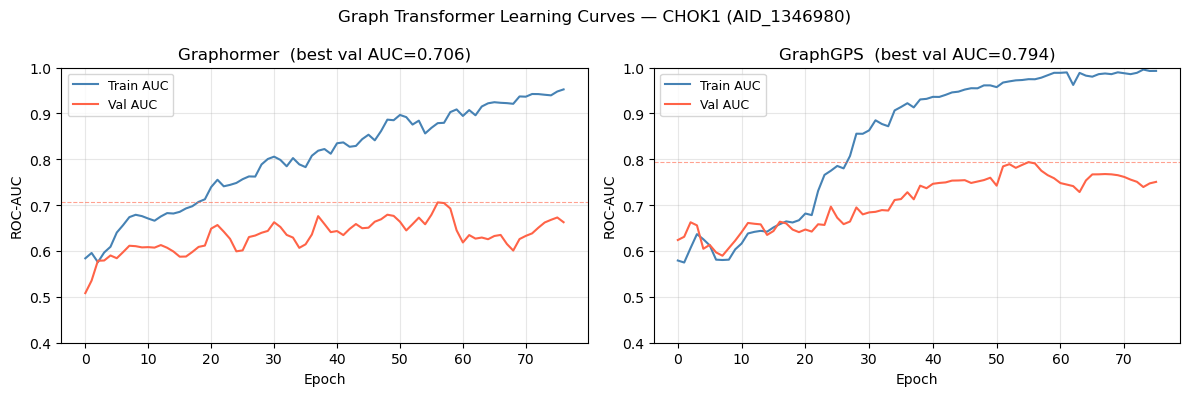

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, arch in zip(axes, ['Graphormer', 'GraphGPS']):
    if arch in gt_history:
        tr, va = gt_history[arch]
        ax.plot(tr, label='Train AUC', color='steelblue')
        ax.plot(va, label='Val AUC',   color='tomato')
        ax.axhline(gt_best_val_auc[arch], color='tomato', ls='--', lw=0.8, alpha=0.6)
        ax.set_title(f'{arch}  (best val AUC={gt_best_val_auc[arch]:.3f})')
        ax.set_xlabel('Epoch'); ax.set_ylabel('ROC-AUC')
        ax.legend(fontsize=9); ax.set_ylim(0.4, 1.0)
        ax.grid(alpha=0.3)
plt.suptitle(f'Graph Transformer Learning Curves — {DATASET_NAME} ({ASSAY_ID})', fontsize=12)
plt.tight_layout()
plt.savefig(f'{OUT_PREFIX}_learning_curves.png', dpi=150)
plt.show()


---
## Step 9 — Test Set Evaluation

Using the **same held-out test set** as `qsar_mito.ipynb` (identical SEED + stratified split).  
Metrics reported at CPT = 0.5 and CPT = 0.8.


In [18]:
gt_probs_test = {}

for arch, state in gt_best_models.items():
    has_pe = (arch == 'GraphGPS')
    cfg    = gt_best_configs[arch]
    h, nh, nl, dr = cfg['hidden'], cfg['num_heads'], cfg['num_layers'], cfg['dropout']

    if arch == 'Graphormer':
        model = GraphormerModel(ATOM_DIM, h, nh, nl, dr).to(DEVICE)
        ldr   = test_loader
    else:
        model = GraphGPSModel(ATOM_DIM, h, PE_DIM, nh, nl, dr).to(DEVICE)
        ldr   = test_loader_gps

    model.load_state_dict(state)
    probs, _, _ = gt_eval(model, ldr, has_pe)
    gt_probs_test[arch] = probs

# Consensus of Graphormer + GraphGPS
if len(gt_probs_test) == 2:
    gt_probs_test['Consensus-GT'] = np.mean(list(gt_probs_test.values()), axis=0)

# Evaluation table
rows = []
for name, prob in gt_probs_test.items():
    for cpt in [0.5, 0.8]:
        rows.append(evaluate(y_test, prob, name, cpt))

df_test = pd.DataFrame(rows)[METRIC_COLS]
print('── Graph Transformer Test Set Results ──')
display(df_test.set_index(['Model','CPT']))
df_test.to_csv(f'{OUT_PREFIX}_test_results.csv', index=False)
print(f'Saved → {OUT_PREFIX}_test_results.csv')

np.save('chok1_gt_probs_test.npy', {k:v for k,v in gt_probs_test.items() if 'Consensus' not in k})
print('GT probs saved.')

── Graph Transformer Test Set Results ──


Sensitivity  Specificity   CCR  ROC-AUC  PR-AUC     MCC  \
Model        CPT                                                            
Graphormer   0.5         69.6         67.8  68.7   0.7728  0.0760  0.0981   
             0.8         26.1         95.6  60.9   0.7728  0.0760  0.1265   
GraphGPS     0.5         82.6         62.2  72.4   0.7897  0.0623  0.1137   
             0.8         73.9         74.2  74.1   0.7897  0.0623  0.1347   
Consensus-GT 0.5         82.6         65.8  74.2   0.8319  0.1230  0.1252   
             0.8         47.8         94.1  71.0   0.8319  0.1230  0.2096   

                  Bal-Acc      F1  
Model        CPT                   
Graphormer   0.5     68.7  0.0626  
             0.8     60.9  0.1290  
GraphGPS     0.5     72.4  0.0639  
             0.8     74.1  0.0815  
Consensus-GT 0.5     74.2  0.0700  
             0.8     71.0  0.1833

Saved → chok1_gt_test_results.csv
GT probs saved.


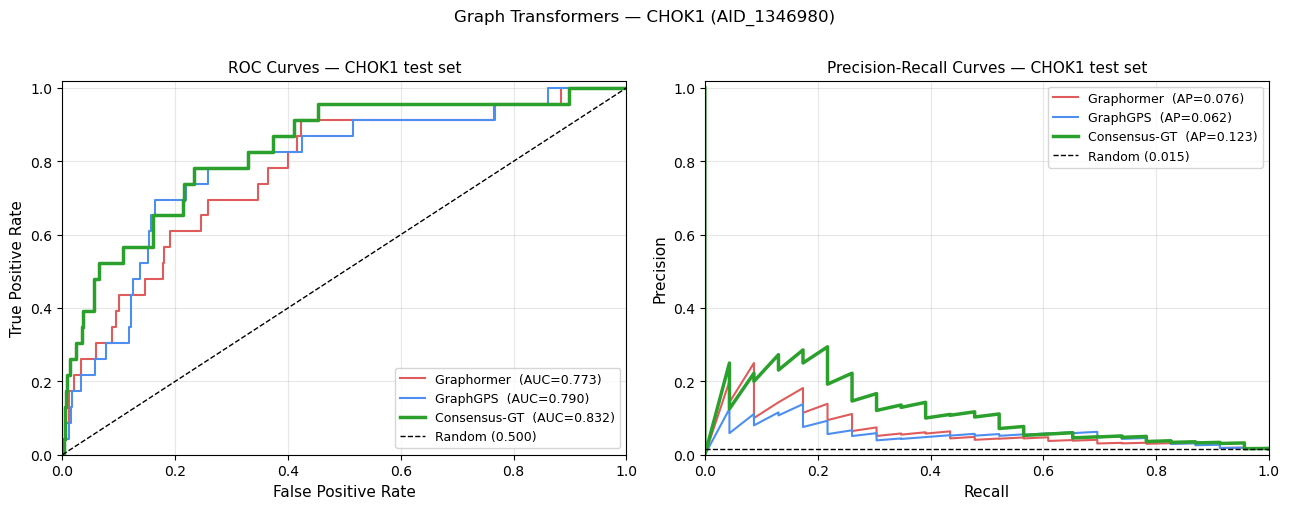

Saved → chok1_gt_roc_pr.png


In [19]:
COLORS = {'Graphormer':'#e05c5c', 'GraphGPS':'#4c8ff0', 'Consensus-GT':'#2ca02c'}

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# ROC
ax = axes[0]
for name, prob in gt_probs_test.items():
    lw  = 2.5 if 'Consensus' in name else 1.5
    fpr, tpr, _ = roc_curve(y_test, prob)
    auc = roc_auc_score(y_test, prob)
    ax.plot(fpr, tpr, lw=lw, color=COLORS.get(name,'gray'),
            label=f'{name}  (AUC={auc:.3f})')
ax.plot([0,1],[0,1],'k--',lw=1,label='Random (0.500)')
ax.set_xlabel('False Positive Rate', fontsize=11)
ax.set_ylabel('True Positive Rate', fontsize=11)
ax.set_title(f'ROC Curves — {DATASET_NAME} test set', fontsize=11)
ax.legend(fontsize=9); ax.grid(alpha=0.3)
ax.set_xlim([0,1]); ax.set_ylim([0,1.02])

# PR
ax2 = axes[1]
baseline = y_test.mean()
for name, prob in gt_probs_test.items():
    lw = 2.5 if 'Consensus' in name else 1.5
    prec, rec, _ = precision_recall_curve(y_test, prob)
    ap = average_precision_score(y_test, prob)
    ax2.plot(rec, prec, lw=lw, color=COLORS.get(name,'gray'),
             label=f'{name}  (AP={ap:.3f})')
ax2.axhline(baseline, color='k', ls='--', lw=1, label=f'Random ({baseline:.3f})')
ax2.set_xlabel('Recall', fontsize=11)
ax2.set_ylabel('Precision', fontsize=11)
ax2.set_title(f'Precision-Recall Curves — {DATASET_NAME} test set', fontsize=11)
ax2.legend(fontsize=9); ax2.grid(alpha=0.3)
ax2.set_xlim([0,1]); ax2.set_ylim([0,1.02])

plt.suptitle(f'Graph Transformers — {DATASET_NAME} ({ASSAY_ID})', fontsize=12, y=1.01)
plt.tight_layout()
plt.savefig(f'{OUT_PREFIX}_roc_pr.png', dpi=150, bbox_inches='tight')
plt.show()
print(f'Saved → {OUT_PREFIX}_roc_pr.png')


In [20]:
# Ranked summary at CPT = 0.5
summary = (df_test[df_test['CPT']==0.5]
           .drop(columns='CPT')
           .set_index('Model')
           .sort_values('ROC-AUC', ascending=False))

print('=' * 75)
print(f'FINAL RANKING — {DATASET_NAME} ({ASSAY_ID}) | CPT = 0.50')
print(f'80/20/20 stratified split | 1:1 downsampled train | SEED={SEED}')
print('=' * 75)
display(summary)

# Best model detail
best_name = summary.index[0]
best_prob = gt_probs_test[best_name]
print(f'\nBest model: {best_name}')
print(f'Best config: {gt_best_configs.get(best_name, "N/A")}')
print(classification_report(y_test, (best_prob>=0.5).astype(int),
                             target_names=['Inactive(0)','Active(1)']))


FINAL RANKING — CHOK1 (AID_1346980) | CPT = 0.50
80/20/20 stratified split | 1:1 downsampled train | SEED=42


,Sensitivity,Specificity,CCR,ROC-AUC,PR-AUC,MCC,Bal-Acc,F1
Model,,,,,,,,
Consensus-GT,82.6,65.8,74.2,0.8319,0.1230,0.1252,74.2,0.0700
GraphGPS,82.6,62.2,72.4,0.7897,0.0623,0.1137,72.4,0.0639
Graphormer,69.6,67.8,68.7,0.7728,0.0760,0.0981,68.7,0.0626



Best model: Consensus-GT
Best config: N/A
              precision    recall  f1-score   support

 Inactive(0)       1.00      0.66      0.79      1464
   Active(1)       0.04      0.83      0.07        23

    accuracy                           0.66      1487
   macro avg       0.52      0.74      0.43      1487
weighted avg       0.98      0.66      0.78      1487



In [21]:
# ── Consensus (Full + GT): RF + SVM + XGB + GCN + GAT + GIN + SAGE + Graphormer + GraphGPS
base = np.load('chok1_base_probs_test.npy', allow_pickle=True).item()
y_te = np.load('chok1_y_test.npy',          allow_pickle=True)
assert np.array_equal(y_te, y_test), "Test sets don't match — check SEED/split!"

print(f'Loaded base models : {list(base.keys())}')
print(f'GT models          : Graphormer, GraphGPS')

all_probs = np.stack(
    list(base.values()) +
    [gt_probs_test['Graphormer'], gt_probs_test['GraphGPS']],
    axis=0
)
print(f'Stacking {all_probs.shape[0]} models over {all_probs.shape[1]} test compounds')

consensus_full_gt = all_probs.mean(axis=0)

rows = []
for cpt in [0.5, 0.8]:
    rows.append(evaluate(y_test, consensus_full_gt, 'Consensus (Full+GT)', cpt))

df_full_gt = pd.DataFrame(rows)[METRIC_COLS]
print('\n── Consensus (Full+GT) Test Results ──')
display(df_full_gt.set_index(['Model','CPT']))
df_full_gt.to_csv(f'{OUT_PREFIX}_consensus_full_gt.csv', index=False)
print(f'Saved → {OUT_PREFIX}_consensus_full_gt.csv')

Loaded base models : ['Random Forest', 'SVM', 'XGBoost', 'GCN', 'GAT', 'GIN', 'SAGE']
GT models          : Graphormer, GraphGPS
Stacking 9 models over 1487 test compounds

── Consensus (Full+GT) Test Results ──


Sensitivity  Specificity   CCR  ROC-AUC  PR-AUC  \
Model               CPT                                                    
Consensus (Full+GT) 0.5         73.9         70.8  72.3   0.7958  0.1636   
                    0.8         21.7         98.4  60.1   0.7958  0.1636   

                            MCC  Bal-Acc      F1  
Model               CPT                           
Consensus (Full+GT) 0.5  0.1204     72.3  0.0726  
                    0.8  0.1831     60.1  0.1961

Saved → chok1_gt_consensus_full_gt.csv


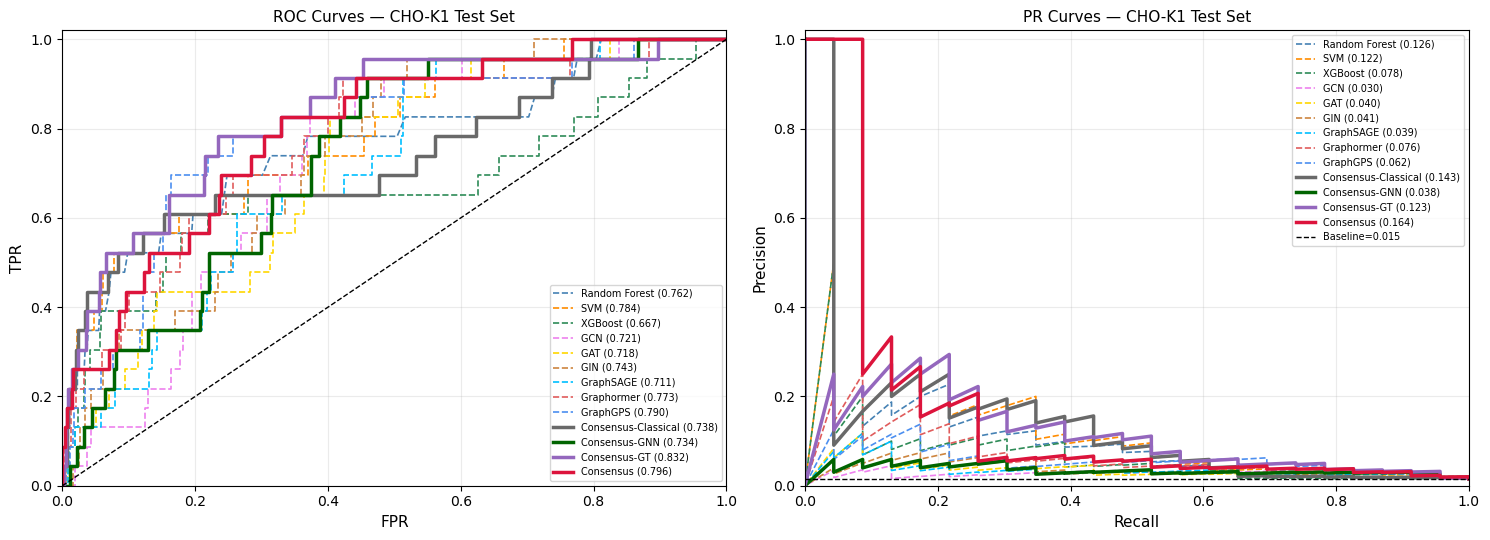

Saved → chok1_gt_roc_pr_all_models.png

── ROC-AUC Ranking (All Models, CHO-K1 Test Set) ──
  Model                       ROC-AUC    PR-AUC
  ------------------------------------------------
  Consensus-GT                 0.8319    0.1230 ◄
  Consensus                    0.7958    0.1636
  GraphGPS                     0.7897    0.0623 ◄
  SVM                          0.7837    0.1223
  Graphormer                   0.7728    0.0760 ◄
  Random Forest                0.7625    0.1258
  GIN                          0.7427    0.0406
  Consensus-Classical          0.7379    0.1430
  Consensus-GNN                0.7336    0.0380
  GCN                          0.7212    0.0303
  GAT                          0.7179    0.0397
  GraphSAGE                    0.7105    0.0391
  XGBoost                      0.6670    0.0783


In [3]:
# ── Combined ROC & PR Curves: All Models + Graph Transformers ─────────────────
# Self-contained: loads all saved probability arrays from disk — no retraining needed.
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, roc_auc_score, precision_recall_curve, average_precision_score

# ── Load saved probabilities ──────────────────────────────────────────────────
base     = np.load('chok1_base_probs_test.npy',  allow_pickle=True).item()
gt_saved = np.load('chok1_gt_probs_test.npy',    allow_pickle=True).item()
y_te     = np.load('chok1_y_test.npy',           allow_pickle=True)

# ── Build complete probability dict ──────────────────────────────────────────
combined = dict(base)
if 'SAGE' in combined:
    combined['GraphSAGE'] = combined.pop('SAGE')

combined['Graphormer'] = gt_saved['Graphormer']
combined['GraphGPS']   = gt_saved['GraphGPS']

combined['Consensus-Classical'] = np.mean([base['Random Forest'], base['SVM'], base['XGBoost']], axis=0)
combined['Consensus-GNN']       = np.mean([base['GCN'], base['GAT'], base['GIN'], base['SAGE']], axis=0)
combined['Consensus-GT']        = np.mean([combined['Graphormer'], combined['GraphGPS']], axis=0)
combined['Consensus']           = np.mean(
    [base['Random Forest'], base['SVM'], base['XGBoost'],
     base['GCN'], base['GAT'], base['GIN'], base['SAGE'],
     combined['Graphormer'], combined['GraphGPS']], axis=0)

# ── Styling ───────────────────────────────────────────────────────────────────
COLORS = {
    'Random Forest'      : 'steelblue',
    'SVM'                : 'darkorange',
    'XGBoost'            : 'seagreen',
    'GCN'                : 'violet',
    'GAT'                : 'gold',
    'GIN'                : 'peru',
    'GraphSAGE'          : 'deepskyblue',
    'Graphormer'         : '#e05c5c',
    'GraphGPS'           : '#4c8ff0',
    'Consensus-Classical': 'dimgray',
    'Consensus-GNN'      : 'darkgreen',
    'Consensus-GT'       : '#9467bd',
    'Consensus'          : 'crimson',
}

LINESTYLE = {name: '-' if 'Consensus' in name else '--' for name in combined}
LINEWIDTH  = {name: 2.5 if 'Consensus' in name else 1.2 for name in combined}

indiv_order     = ['Random Forest', 'SVM', 'XGBoost',
                   'GCN', 'GAT', 'GIN', 'GraphSAGE',
                   'Graphormer', 'GraphGPS']
consensus_order = ['Consensus-Classical', 'Consensus-GNN',
                   'Consensus-GT', 'Consensus']
plot_order = indiv_order + consensus_order

# ── Plot ──────────────────────────────────────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))

for name in plot_order:
    prob = combined[name]
    c    = COLORS.get(name, 'gray')
    ls   = LINESTYLE[name]
    lw   = LINEWIDTH[name]

    fpr, tpr, _ = roc_curve(y_te, prob)
    auc = roc_auc_score(y_te, prob)
    axes[0].plot(fpr, tpr, lw=lw, color=c, ls=ls, label=f'{name} ({auc:.3f})')

    pre, rec, _ = precision_recall_curve(y_te, prob)
    ap = average_precision_score(y_te, prob)
    axes[1].plot(rec, pre, lw=lw, color=c, ls=ls, label=f'{name} ({ap:.3f})')

axes[0].plot([0, 1], [0, 1], 'k--', lw=1)
axes[0].set_xlabel('FPR', fontsize=11)
axes[0].set_ylabel('TPR', fontsize=11)
axes[0].set_title('ROC Curves — CHO-K1 Test Set', fontsize=11)
axes[0].legend(fontsize=7, loc='lower right', ncol=1)
axes[0].set_xlim([0, 1]); axes[0].set_ylim([0, 1.02])
axes[0].grid(alpha=0.25)

baseline = y_te.mean()
axes[1].axhline(baseline, color='k', ls='--', lw=1, label=f'Baseline={baseline:.3f}')
axes[1].set_xlabel('Recall', fontsize=11)
axes[1].set_ylabel('Precision', fontsize=11)
axes[1].set_title('PR Curves — CHO-K1 Test Set', fontsize=11)
axes[1].legend(fontsize=7, loc='upper right', ncol=1)
axes[1].set_xlim([0, 1]); axes[1].set_ylim([0, 1.02])
axes[1].grid(alpha=0.25)

plt.tight_layout()
plt.savefig('chok1_gt_roc_pr_all_models.png', dpi=150, bbox_inches='tight')
plt.show()
print('Saved → chok1_gt_roc_pr_all_models.png')

# ── Quick ranked AUC summary ──────────────────────────────────────────────────
print('\n── ROC-AUC Ranking (All Models, CHO-K1 Test Set) ──')
auc_rows = [(name, round(roc_auc_score(y_te, p), 4),
             round(average_precision_score(y_te, p), 4))
            for name, p in combined.items()]
auc_rows.sort(key=lambda x: x[1], reverse=True)
print(f'  {"Model":<25} {"ROC-AUC":>9}  {"PR-AUC":>8}')
print('  ' + '-'*48)
for name, ra, pa in auc_rows:
    marker = ' ◄' if 'GT' in name or name in ('Graphormer', 'GraphGPS') else ''
    print(f'  {name:<25} {ra:>9.4f}  {pa:>8.4f}{marker}')
